## WorldTrace User Normal Pattern and Anomaly (Flag 6)

### Dataset Overview
A point-level table containing 40 car trajectories from one user, with route geometry, start and end regions, speed, distance, and route-indirectness summaries.

The notebook exposes the primary analysis table.

Goal: Analyze the provided user's normal movement pattern and identify anomalous trajectories.

Role: NYC mobility insight analyst


Category: User Normal Pattern and Anomaly

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "06_user_normal_pattern_and_anomaly_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

### **Question 1**: What proportion of the user's trajectories belongs to the bidirectional Area A–Area B corridor, and how is it split by direction?

#### Analysis action

Use the bidirectional corridor as the user's dominant movement pattern before interpreting the remaining trajectories as exceptions or regional variation.

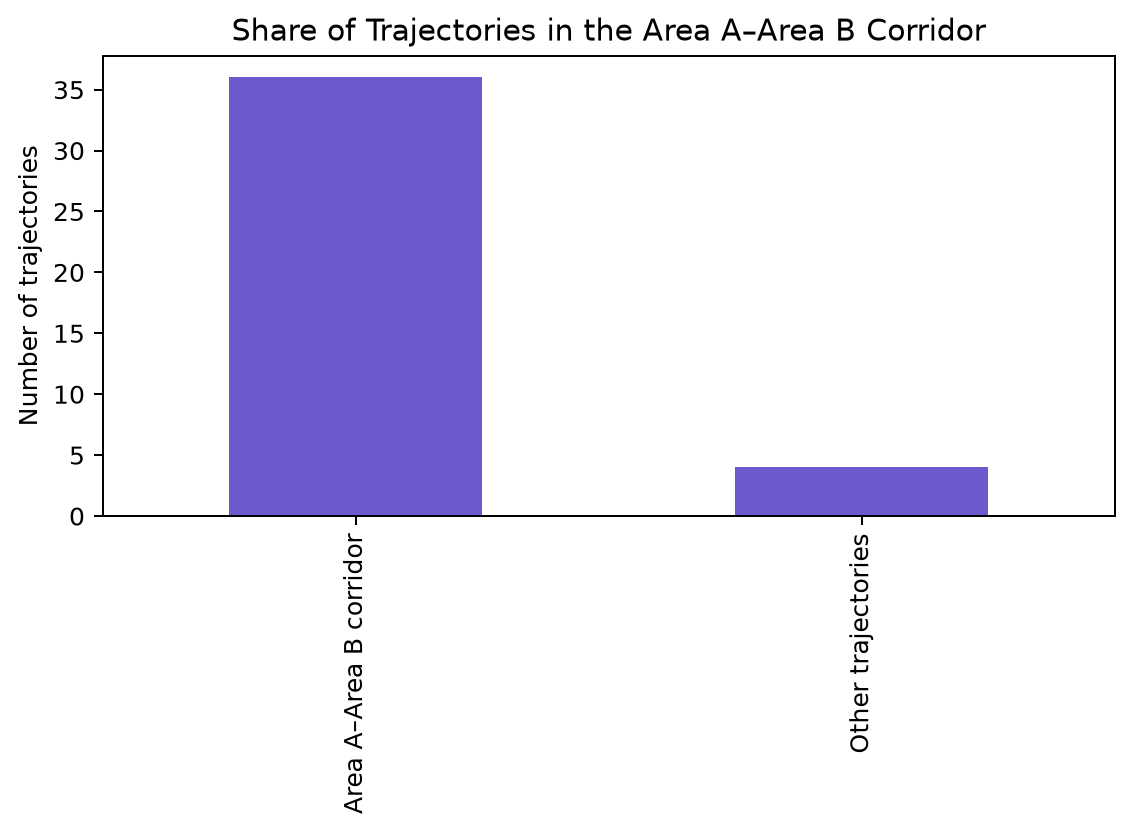

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

summary = df.drop_duplicates("trajectory_id").copy()
is_ab = (((summary["start_region"] == "Area A (South Brooklyn)") & (summary["end_region"] == "Area B (Lower Manhattan)")) | ((summary["start_region"] == "Area B (Lower Manhattan)") & (summary["end_region"] == "Area A (South Brooklyn)")))
summary["trajectory_group"] = is_ab.map({True: "Area A–Area B corridor", False: "Other trajectories"})
summary["direction"] = "Other"
summary.loc[(summary["start_region"] == "Area A (South Brooklyn)") & (summary["end_region"] == "Area B (Lower Manhattan)"), "direction"] = "A to B"
summary.loc[(summary["start_region"] == "Area B (Lower Manhattan)") & (summary["end_region"] == "Area A (South Brooklyn)"), "direction"] = "B to A"

report = pd.DataFrame({"count": [len(summary), int(is_ab.sum()), int((~is_ab).sum()), int((summary["direction"] == "A to B").sum()), int((summary["direction"] == "B to A").sum())]}, index=["All trajectories", "Area A–Area B corridor", "Other trajectories", "A to B", "B to A"])
report["share"] = report["count"] / len(summary)
print(report)
report.loc[["Area A–Area B corridor", "Other trajectories"]]["count"].plot(kind="bar", color="slateblue")
plt.title("Share of Trajectories in the Area A–Area B Corridor")
plt.ylabel("Number of trajectories")
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "The user repeatedly travels between Area A and Area B: 36 of 40 trajectories, or 90%, belong to this bidirectional corridor, with 18 trips in each direction.",
  "insight_value": {
    "total_trajectories": 40,
    "area_a_to_area_b": 18,
    "area_b_to_area_a": 18,
    "bidirectional_corridor_trajectories": 36,
    "bidirectional_corridor_share": 0.9
  },
  "plot": {
    "plot_type": "bar_and_table",
    "title": "Share of Trajectories in the Area A–Area B Corridor",
    "x_axis": {
      "name": "Trajectory group or direction",
      "description": "The bidirectional Area A–Area B corridor versus all other trajectories."
    },
    "y_axis": {
      "name": "Number of trajectories",
      "description": "The number of unique trajectories in each group."
    },
    "description": "The table reports the total, both directions, and the corridor share; the bar chart makes the 90% concentration visible.",
    "file": "notebook_plots/q1_1.png"
  },
  "question": "What proportion of the user's trajectories belongs to the bidirectional Area A–Area B corridor, and how is it split by direction?",
  "actionable_insight": "Use the bidirectional corridor as the user's dominant movement pattern before interpreting the remaining trajectories as exceptions or regional variation.",
  "code": "import matplotlib.pyplot as plt\nimport pandas as pd\n\nsummary = df.drop_duplicates(\"trajectory_id\").copy()\nis_ab = (((summary[\"start_region\"] == \"Area A (South Brooklyn)\") & (summary[\"end_region\"] == \"Area B (Lower Manhattan)\")) | ((summary[\"start_region\"] == \"Area B (Lower Manhattan)\") & (summary[\"end_region\"] == \"Area A (South Brooklyn)\")))\nsummary[\"trajectory_group\"] = is_ab.map({True: \"Area A–Area B corridor\", False: \"Other trajectories\"})\nsummary[\"direction\"] = \"Other\"\nsummary.loc[(summary[\"start_region\"] == \"Area A (South Brooklyn)\") & (summary[\"end_region\"] == \"Area B (Lower Manhattan)\"), \"direction\"] = \"A to B\"\nsummary.loc[(summary[\"start_region\"] == \"Area B (Lower Manhattan)\") & (summary[\"end_region\"] == \"Area A (South Brooklyn)\"), \"direction\"] = \"B to A\"\n\nreport = pd.DataFrame({\"count\": [len(summary), int(is_ab.sum()), int((~is_ab).sum()), int((summary[\"direction\"] == \"A to B\").sum()), int((summary[\"direction\"] == \"B to A\").sum())]}, index=[\"All trajectories\", \"Area A–Area B corridor\", \"Other trajectories\", \"A to B\", \"B to A\"])\nreport[\"share\"] = report[\"count\"] / len(summary)\nprint(report)\nreport.loc[[\"Area A–Area B corridor\", \"Other trajectories\"]][\"count\"].plot(kind=\"bar\", color=\"slateblue\")\nplt.title(\"Share of Trajectories in the Area A–Area B Corridor\")\nplt.ylabel(\"Number of trajectories\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: How much do the user's routes and traveled distances vary when driving between Area A and Area B?

#### Analysis action

Inspect route geometry together with traveled distance; the shared endpoints do not imply one fixed road choice or one typical distance.

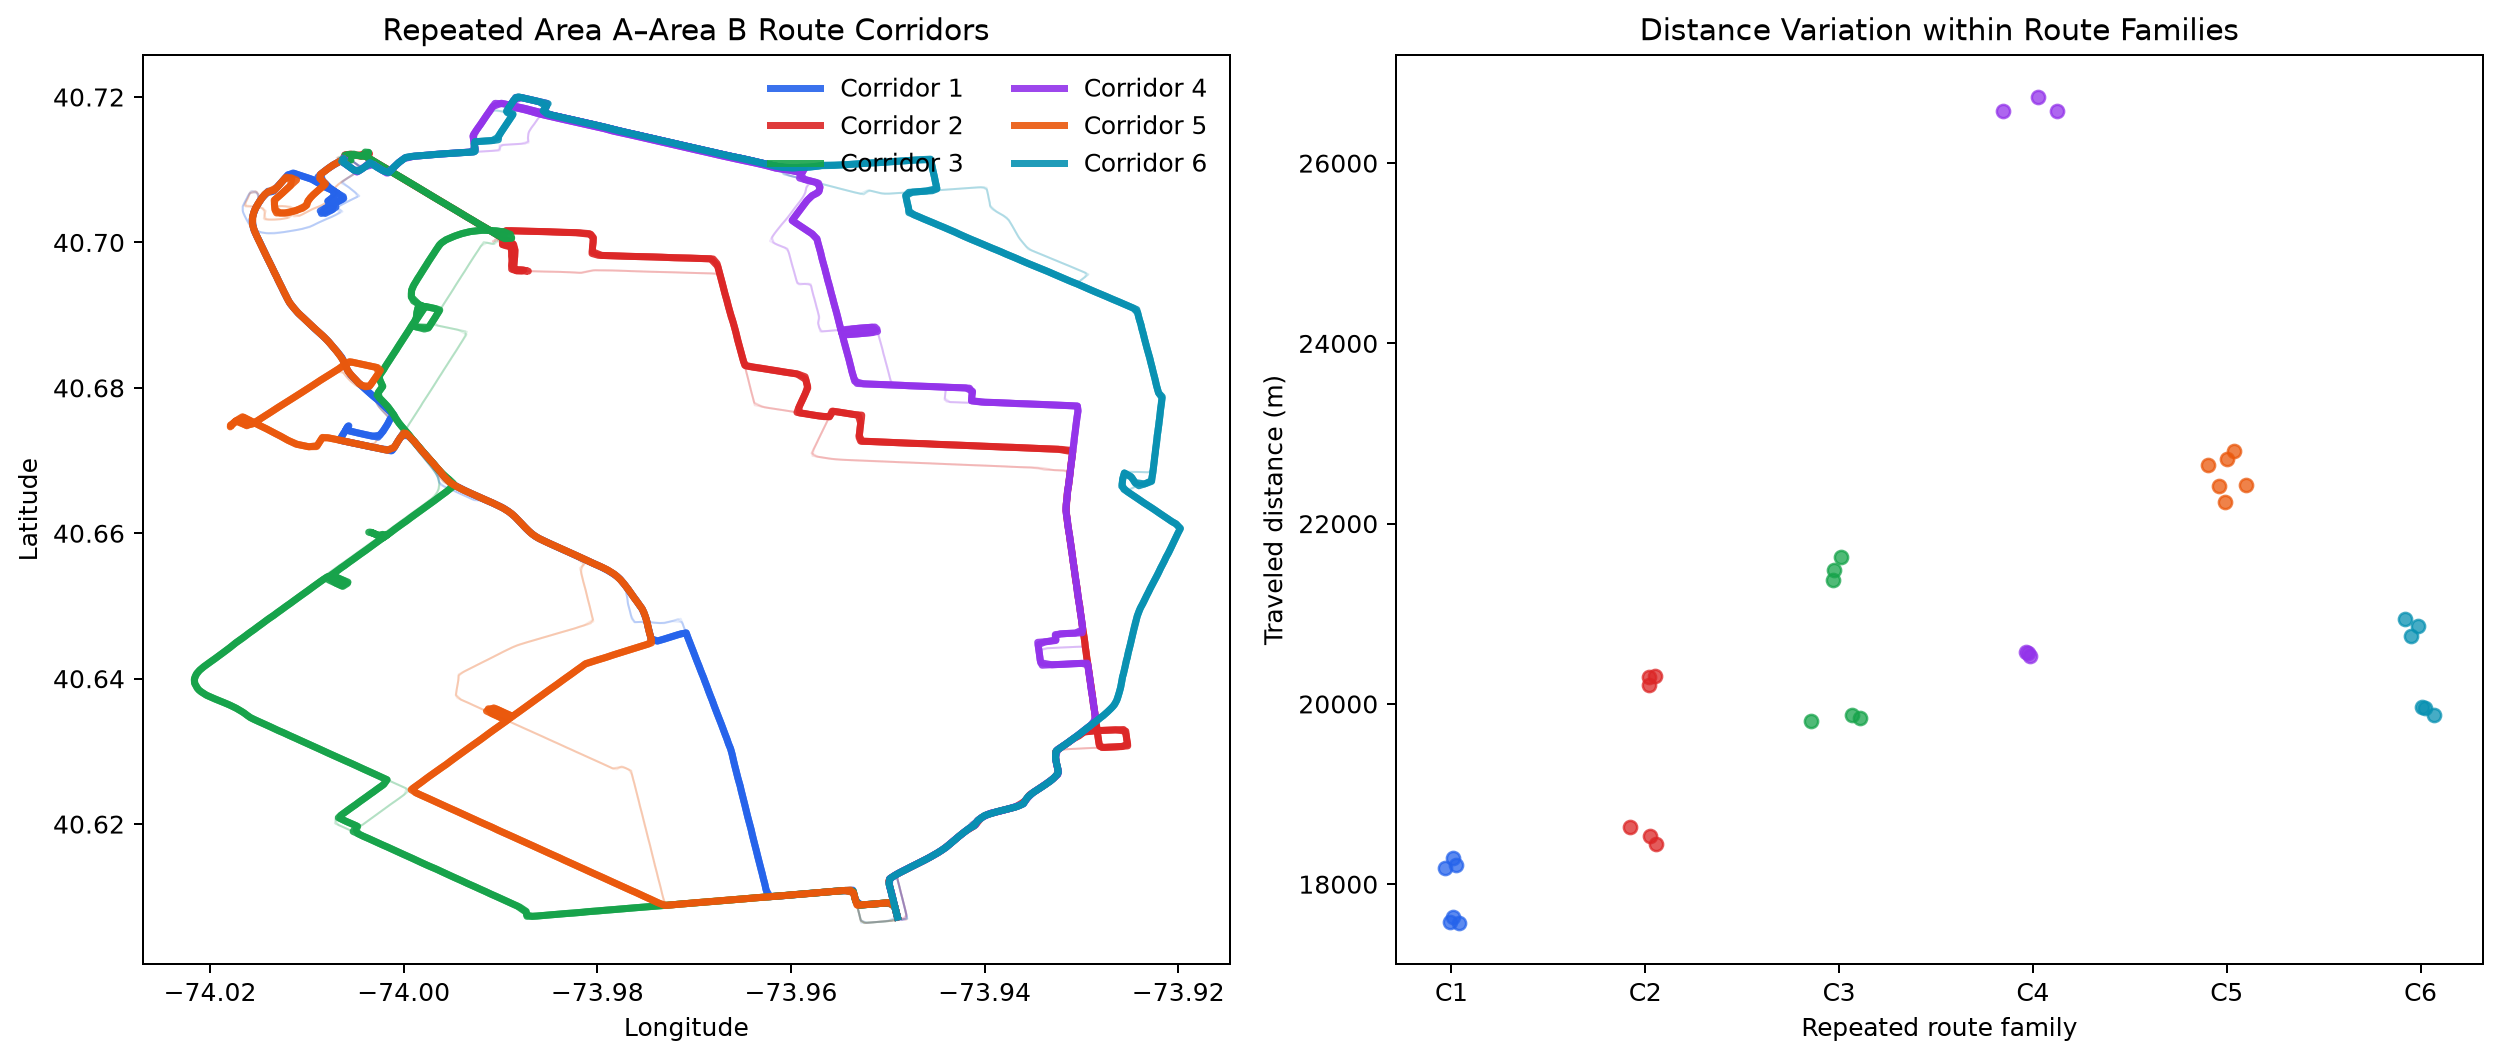

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

summary = df.drop_duplicates("trajectory_id").copy()
is_ab = (((summary["start_region"] == "Area A (South Brooklyn)") & (summary["end_region"] == "Area B (Lower Manhattan)")) | ((summary["start_region"] == "Area B (Lower Manhattan)") & (summary["end_region"] == "Area A (South Brooklyn)")))
ab_ids = set(summary.loc[is_ab, "trajectory_id"])
route_points = df[df["trajectory_id"].isin(ab_ids)].sort_values(["trajectory_id", "point_index"])

def corridor_family(trajectory_id):
 number = int(trajectory_id.rsplit("_", 1)[1])
 return (number - 1) % 6 if number <= 18 else ((number - 19) + 1) % 6

route_points["corridor_family"] = route_points["trajectory_id"].map(corridor_family)
palette = ["#2563eb", "#dc2626", "#16a34a", "#9333ea", "#ea580c", "#0891b2"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for trajectory_id, trip in route_points.groupby("trajectory_id"):
 family = int(trip["corridor_family"].iloc[0])
 axes[0].plot(trip["longitude"], trip["latitude"], color=palette[family], alpha=0.12, linewidth=0.8)
for family, group in route_points.groupby("corridor_family"):
 family_ids = group["trajectory_id"].drop_duplicates().tolist()
 for trajectory_id in family_ids[:2]:
  trip = group[group["trajectory_id"] == trajectory_id]
  label = f"Corridor {int(family)+1}" if trajectory_id == family_ids[0] else None
  axes[0].plot(trip["longitude"], trip["latitude"], color=palette[int(family)], alpha=0.9, linewidth=2.8, label=label)
axes[0].set_title("Repeated Area A–Area B Route Corridors")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
axes[0].legend(frameon=False, ncol=2)
for family, group in route_points.groupby("corridor_family"):
 values = group.drop_duplicates("trajectory_id")["distance_meters"].astype(float)
 axes[1].scatter(np.full(len(values), int(family)) + np.random.default_rng(int(family)).normal(0, 0.06, len(values)), values, color=palette[int(family)], alpha=0.75, s=28)
axes[1].set_xticks(range(6), [f"C{i}" for i in range(1, 7)])
axes[1].set_title("Distance Variation within Route Families")
axes[1].set_xlabel("Repeated route family"); axes[1].set_ylabel("Traveled distance (m)")
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "When driving between Area A and Area B, the user takes multiple route corridors, and traveled distances vary widely across these trips.",
  "insight_value": {
    "area_a_area_b_distance_range_m": [
      17567.5,
      26738.6
    ],
    "area_a_area_b_route_variants": 6
  },
  "plot": {
    "plot_type": "route_family_map_and_distance_distribution",
    "title": "Repeated Area A–Area B Route Corridors and Distance Variation",
    "description": "All corridor trajectories are drawn faintly, while six repeated route families are overlaid in distinct colors and thicker lines. A companion distribution shows the wide distance range.",
    "file": "notebook_plots/q2_1.png"
  },
  "question": "How much do the user's routes and traveled distances vary when driving between Area A and Area B?",
  "actionable_insight": "Inspect route geometry together with traveled distance; the shared endpoints do not imply one fixed road choice or one typical distance.",
  "code": "import matplotlib.pyplot as plt\nimport numpy as np\n\nsummary = df.drop_duplicates(\"trajectory_id\").copy()\nis_ab = (((summary[\"start_region\"] == \"Area A (South Brooklyn)\") & (summary[\"end_region\"] == \"Area B (Lower Manhattan)\")) | ((summary[\"start_region\"] == \"Area B (Lower Manhattan)\") & (summary[\"end_region\"] == \"Area A (South Brooklyn)\")))\nab_ids = set(summary.loc[is_ab, \"trajectory_id\"])\nroute_points = df[df[\"trajectory_id\"].isin(ab_ids)].sort_values([\"trajectory_id\", \"point_index\"])\n\ndef corridor_family(trajectory_id):\n number = int(trajectory_id.rsplit(\"_\", 1)[1])\n return (number - 1) % 6 if number <= 18 else ((number - 19) + 1) % 6\n\nroute_points[\"corridor_family\"] = route_points[\"trajectory_id\"].map(corridor_family)\npalette = [\"#2563eb\", \"#dc2626\", \"#16a34a\", \"#9333ea\", \"#ea580c\", \"#0891b2\"]\nfig, axes = plt.subplots(1, 2, figsize=(14, 6))\nfor trajectory_id, trip in route_points.groupby(\"trajectory_id\"):\n family = int(trip[\"corridor_family\"].iloc[0])\n axes[0].plot(trip[\"longitude\"], trip[\"latitude\"], color=palette[family], alpha=0.12, linewidth=0.8)\nfor family, group in route_points.groupby(\"corridor_family\"):\n family_ids = group[\"trajectory_id\"].drop_duplicates().tolist()\n for trajectory_id in family_ids[:2]:\n  trip = group[group[\"trajectory_id\"] == trajectory_id]\n  label = f\"Corridor {int(family)+1}\" if trajectory_id == family_ids[0] else None\n  axes[0].plot(trip[\"longitude\"], trip[\"latitude\"], color=palette[int(family)], alpha=0.9, linewidth=2.8, label=label)\naxes[0].set_title(\"Repeated Area A–Area B Route Corridors\")\naxes[0].set_xlabel(\"Longitude\"); axes[0].set_ylabel(\"Latitude\")\naxes[0].legend(frameon=False, ncol=2)\nfor family, group in route_points.groupby(\"corridor_family\"):\n values = group.drop_duplicates(\"trajectory_id\")[\"distance_meters\"].astype(float)\n axes[1].scatter(np.full(len(values), int(family)) + np.random.default_rng(int(family)).normal(0, 0.06, len(values)), values, color=palette[int(family)], alpha=0.75, s=28)\naxes[1].set_xticks(range(6), [f\"C{i}\" for i in range(1, 7)])\naxes[1].set_title(\"Distance Variation within Route Families\")\naxes[1].set_xlabel(\"Repeated route family\"); axes[1].set_ylabel(\"Traveled distance (m)\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: How are the trajectories outside the main Area A–Area B corridor distributed across regions?

#### Analysis action

Treat the non-corridor trajectories as geographically dispersed cases rather than as a second dominant regional route pattern.

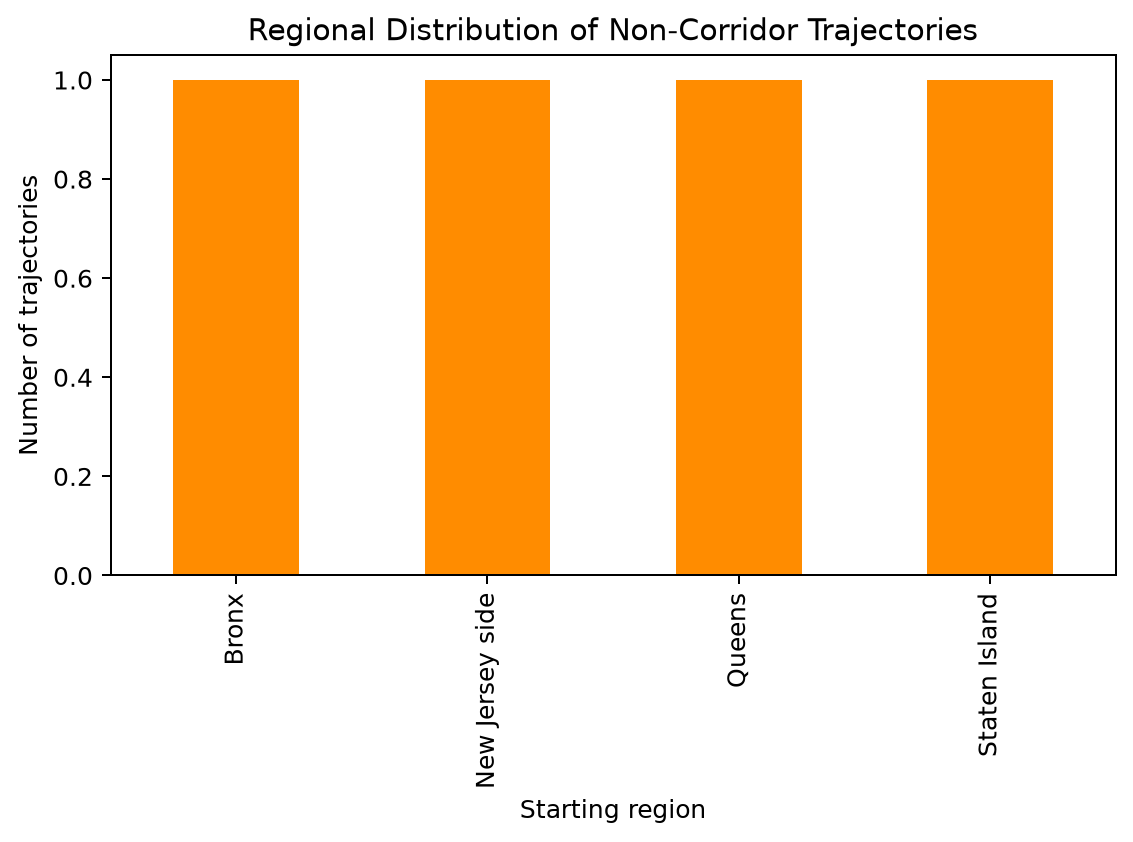

In [ ]:
import matplotlib.pyplot as plt

summary = df.drop_duplicates("trajectory_id").copy()
is_ab = (((summary["start_region"] == "Area A (South Brooklyn)") & (summary["end_region"] == "Area B (Lower Manhattan)")) | ((summary["start_region"] == "Area B (Lower Manhattan)") & (summary["end_region"] == "Area A (South Brooklyn)")))
other = summary.loc[~is_ab]
counts = other["start_region_coarse"].value_counts().sort_index()
counts.plot(kind="bar", color="darkorange")
plt.title("Regional Distribution of Non-Corridor Trajectories")
plt.xlabel("Starting region")
plt.ylabel("Number of trajectories")
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Outside the main Area A–Area B corridor, the remaining four trajectories are evenly distributed across four regions, with one trajectory in each region.",
  "insight_value": {
    "remaining_trajectory_count": 4,
    "region_counts": {
      "Queens": 1,
      "New Jersey side": 1,
      "Bronx": 1,
      "Staten Island": 1
    }
  },
  "plot": {
    "plot_type": "bar",
    "title": "Regional Distribution of Non-Corridor Trajectories",
    "x_axis": {
      "name": "Starting region",
      "description": "The coarse starting region of trajectories outside the main corridor."
    },
    "y_axis": {
      "name": "Number of trajectories",
      "description": "The number of non-corridor trajectories in each region."
    },
    "description": "The regional count plot shows the even one-per-region distribution of the remaining trajectories.",
    "file": "notebook_plots/q3_1.png"
  },
  "question": "How are the trajectories outside the main Area A–Area B corridor distributed across regions?",
  "actionable_insight": "Treat the non-corridor trajectories as geographically dispersed cases rather than as a second dominant regional route pattern.",
  "code": "import matplotlib.pyplot as plt\n\nsummary = df.drop_duplicates(\"trajectory_id\").copy()\nis_ab = (((summary[\"start_region\"] == \"Area A (South Brooklyn)\") & (summary[\"end_region\"] == \"Area B (Lower Manhattan)\")) | ((summary[\"start_region\"] == \"Area B (Lower Manhattan)\") & (summary[\"end_region\"] == \"Area A (South Brooklyn)\")))\nother = summary.loc[~is_ab]\ncounts = other[\"start_region_coarse\"].value_counts().sort_index()\ncounts.plot(kind=\"bar\", color=\"darkorange\")\nplt.title(\"Regional Distribution of Non-Corridor Trajectories\")\nplt.xlabel(\"Starting region\")\nplt.ylabel(\"Number of trajectories\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 4**: How consistent are the user's driving speeds across the main corridor and the other regional trips?

#### Analysis action

Use the narrow observed speed distribution as the user's normal driving-speed profile across regions, while avoiding claims about the reason for that stability.

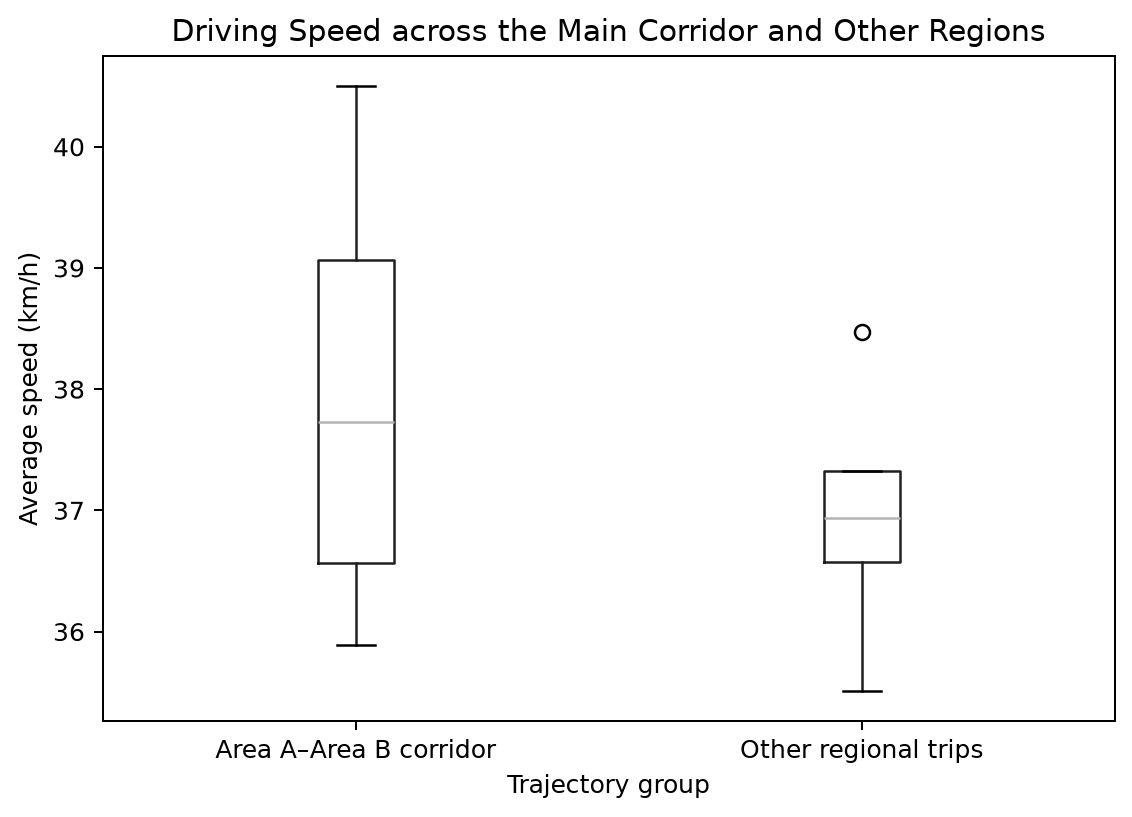

In [ ]:
import matplotlib.pyplot as plt

summary = df.drop_duplicates("trajectory_id").copy()
is_ab = (((summary["start_region"] == "Area A (South Brooklyn)") & (summary["end_region"] == "Area B (Lower Manhattan)")) | ((summary["start_region"] == "Area B (Lower Manhattan)") & (summary["end_region"] == "Area A (South Brooklyn)")))
summary["trajectory_group"] = is_ab.map({True: "Area A–Area B corridor", False: "Other regional trips"})
summary.boxplot(column="avg_speed_kmh", by="trajectory_group", grid=False)
plt.suptitle("")
plt.title("Driving Speed across the Main Corridor and Other Regions")
plt.xlabel("Trajectory group")
plt.ylabel("Average speed (km/h)")
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q4_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "The user's driving speeds are tightly clustered within a narrow range across both the main corridor and the other regional trips, including the less urban regional routes.",
  "insight_value": {
    "overall_speed_range_kmh": [
      35.507613,
      40.499242
    ],
    "main_corridor_speed_range_kmh": [
      35.8932,
      40.499242
    ],
    "other_regional_speed_range_kmh": [
      35.507613,
      38.473023
    ]
  },
  "plot": {
    "plot_type": "boxplot",
    "title": "Driving Speed across the Main Corridor and Other Regions",
    "x_axis": {
      "name": "Trajectory group",
      "description": "The main Area A–Area B corridor or the other regional trips."
    },
    "y_axis": {
      "name": "Average speed (km/h)",
      "description": "The trajectory-level average driving speed."
    },
    "description": "The grouped distribution tests whether the user's speed range changes substantially outside the main urban corridor.",
    "file": "notebook_plots/q4_1.png"
  },
  "question": "How consistent are the user's driving speeds across the main corridor and the other regional trips?",
  "actionable_insight": "Use the narrow observed speed distribution as the user's normal driving-speed profile across regions, while avoiding claims about the reason for that stability.",
  "code": "import matplotlib.pyplot as plt\n\nsummary = df.drop_duplicates(\"trajectory_id\").copy()\nis_ab = (((summary[\"start_region\"] == \"Area A (South Brooklyn)\") & (summary[\"end_region\"] == \"Area B (Lower Manhattan)\")) | ((summary[\"start_region\"] == \"Area B (Lower Manhattan)\") & (summary[\"end_region\"] == \"Area A (South Brooklyn)\")))\nsummary[\"trajectory_group\"] = is_ab.map({True: \"Area A–Area B corridor\", False: \"Other regional trips\"})\nsummary.boxplot(column=\"avg_speed_kmh\", by=\"trajectory_group\", grid=False)\nplt.suptitle(\"\")\nplt.title(\"Driving Speed across the Main Corridor and Other Regions\")\nplt.xlabel(\"Trajectory group\")\nplt.ylabel(\"Average speed (km/h)\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 5**: Which trajectory is the closed-loop exception, and what geometric property distinguishes it from the other trajectories?

#### Analysis action

Flag the closed-loop trajectory as a route-shape exception based on its geometry, not on speed or distance alone.

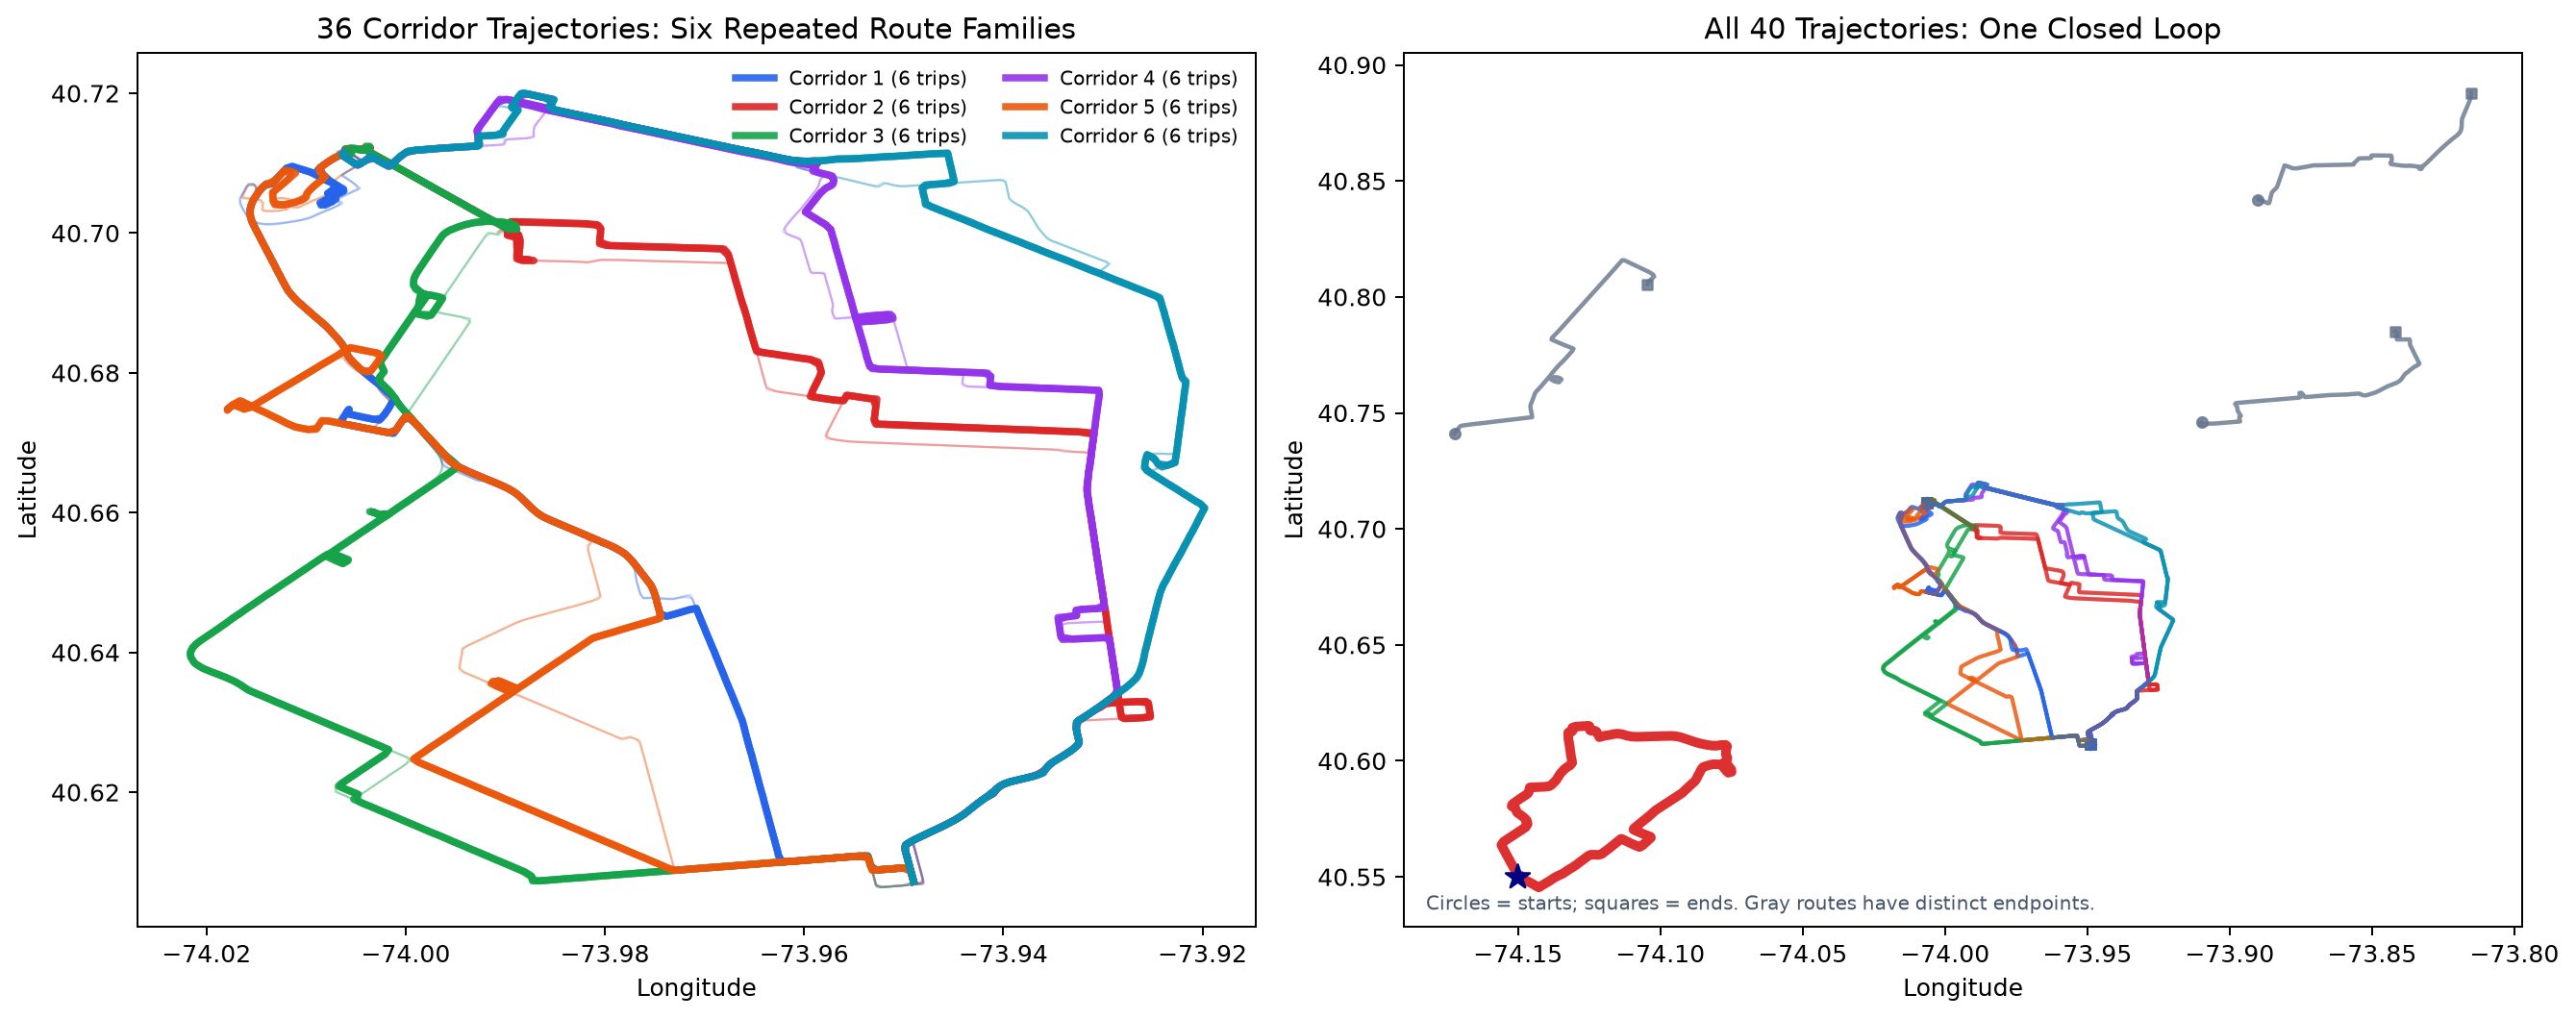

In [ ]:
import matplotlib.pyplot as plt

ordered = df.sort_values(["trajectory_id", "point_index"])
summary = ordered.drop_duplicates("trajectory_id")
is_main = summary["trajectory_id"].str.startswith("user051_main_")
main_ids = set(summary.loc[is_main, "trajectory_id"])

def corridor_family(trajectory_id):
 number = int(trajectory_id.rsplit("_", 1)[1])
 return (number - 1) % 6 if number <= 18 else ((number - 19) + 1) % 6

route_endpoints = []
for trajectory_id, group in ordered.groupby("trajectory_id"):
 first, last = group.iloc[0], group.iloc[-1]
 gap = ((float(last["latitude"]) - float(first["latitude"])) ** 2 + (float(last["longitude"]) - float(first["longitude"])) ** 2) ** 0.5
 route_endpoints.append((trajectory_id, gap))
loop_id = min(route_endpoints, key=lambda item: item[1])[0]
palette = ["#2563eb", "#dc2626", "#16a34a", "#9333ea", "#ea580c", "#0891b2"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for trajectory_id, trip in ordered[ordered["trajectory_id"].isin(main_ids)].groupby("trajectory_id"):
 family = corridor_family(trajectory_id)
 axes[0].plot(trip["longitude"], trip["latitude"], color=palette[family], alpha=0.18, linewidth=0.9)
for family in range(6):
 family_ids = sorted(tid for tid in main_ids if corridor_family(tid) == family)
 for trajectory_id in family_ids[:2]:
  trip = ordered[ordered["trajectory_id"] == trajectory_id]
  label = f"Corridor {family+1} ({len(family_ids)} trips)" if trajectory_id == family_ids[0] else None
  axes[0].plot(trip["longitude"], trip["latitude"], color=palette[family], linewidth=3.0, alpha=0.9, label=label)
for trajectory_id, trip in ordered.groupby("trajectory_id"):
 if trajectory_id == loop_id:
  color, width, alpha = "#dc2626", 4.0, 0.95
 elif trajectory_id in main_ids:
  color, width, alpha = palette[corridor_family(trajectory_id)], 1.6, 0.45
 else:
  color, width, alpha = "#64748b", 1.8, 0.8
 axes[1].plot(trip["longitude"], trip["latitude"], color=color, linewidth=width, alpha=alpha)
 axes[1].scatter(trip["longitude"].iloc[0], trip["latitude"].iloc[0], color=color, marker="o", s=18, alpha=alpha)
 axes[1].scatter(trip["longitude"].iloc[-1], trip["latitude"].iloc[-1], color=color, marker="s", s=18, alpha=alpha)
loop = ordered[ordered["trajectory_id"] == loop_id]
axes[1].scatter(loop["longitude"].iloc[0], loop["latitude"].iloc[0], color="navy", marker="*", s=110, label=f"Closed loop: {loop_id}", zorder=5)
axes[0].set_title("36 Corridor Trajectories: Six Repeated Route Families")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].legend(frameon=False, fontsize=8, ncol=2)
axes[1].set_title("All 40 Trajectories: One Closed Loop")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
axes[1].text(0.02, 0.02, "Circles = starts; squares = ends. Gray routes have distinct endpoints.", transform=axes[1].transAxes, fontsize=8, color="#475569")
plt.tight_layout()
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q5_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "anomaly",
  "insight": "Exactly one trajectory is a route-shape anomaly: it forms a loop and starts and ends at the same geographic point, unlike the other trajectories.",
  "insight_value": {
    "anomaly_trajectory_id": "user051_other_04",
    "anomaly_region": "Staten Island",
    "endpoint_gap_m": 0.0,
    "anomaly_type": "closed loop"
  },
  "plot": {
    "plot_type": "multi_scale_route_map",
    "title": "Repeated Corridor Routes and the Single Closed Loop",
    "description": "The left panel expands the 36 corridor trajectories into six colored repeated route families; the right panel shows all trajectories, with the single closed loop in red and start/end markers on every route.",
    "file": "notebook_plots/q5_1.png"
  },
  "question": "Which trajectory is the closed-loop exception, and what geometric property distinguishes it from the other trajectories?",
  "actionable_insight": "Flag the closed-loop trajectory as a route-shape exception based on its geometry, not on speed or distance alone.",
  "code": "import matplotlib.pyplot as plt\n\nordered = df.sort_values([\"trajectory_id\", \"point_index\"])\nsummary = ordered.drop_duplicates(\"trajectory_id\")\nis_main = summary[\"trajectory_id\"].str.startswith(\"user051_main_\")\nmain_ids = set(summary.loc[is_main, \"trajectory_id\"])\n\ndef corridor_family(trajectory_id):\n number = int(trajectory_id.rsplit(\"_\", 1)[1])\n return (number - 1) % 6 if number <= 18 else ((number - 19) + 1) % 6\n\nroute_endpoints = []\nfor trajectory_id, group in ordered.groupby(\"trajectory_id\"):\n first, last = group.iloc[0], group.iloc[-1]\n gap = ((float(last[\"latitude\"]) - float(first[\"latitude\"])) ** 2 + (float(last[\"longitude\"]) - float(first[\"longitude\"])) ** 2) ** 0.5\n route_endpoints.append((trajectory_id, gap))\nloop_id = min(route_endpoints, key=lambda item: item[1])[0]\npalette = [\"#2563eb\", \"#dc2626\", \"#16a34a\", \"#9333ea\", \"#ea580c\", \"#0891b2\"]\nfig, axes = plt.subplots(1, 2, figsize=(15, 6))\nfor trajectory_id, trip in ordered[ordered[\"trajectory_id\"].isin(main_ids)].groupby(\"trajectory_id\"):\n family = corridor_family(trajectory_id)\n axes[0].plot(trip[\"longitude\"], trip[\"latitude\"], color=palette[family], alpha=0.18, linewidth=0.9)\nfor family in range(6):\n family_ids = sorted(tid for tid in main_ids if corridor_family(tid) == family)\n for trajectory_id in family_ids[:2]:\n  trip = ordered[ordered[\"trajectory_id\"] == trajectory_id]\n  label = f\"Corridor {family+1} ({len(family_ids)} trips)\" if trajectory_id == family_ids[0] else None\n  axes[0].plot(trip[\"longitude\"], trip[\"latitude\"], color=palette[family], linewidth=3.0, alpha=0.9, label=label)\nfor trajectory_id, trip in ordered.groupby(\"trajectory_id\"):\n if trajectory_id == loop_id:\n  color, width, alpha = \"#dc2626\", 4.0, 0.95\n elif trajectory_id in main_ids:\n  color, width, alpha = palette[corridor_family(trajectory_id)], 1.6, 0.45\n else:\n  color, width, alpha = \"#64748b\", 1.8, 0.8\n axes[1].plot(trip[\"longitude\"], trip[\"latitude\"], color=color, linewidth=width, alpha=alpha)\n axes[1].scatter(trip[\"longitude\"].iloc[0], trip[\"latitude\"].iloc[0], color=color, marker=\"o\", s=18, alpha=alpha)\n axes[1].scatter(trip[\"longitude\"].iloc[-1], trip[\"latitude\"].iloc[-1], color=color, marker=\"s\", s=18, alpha=alpha)\nloop = ordered[ordered[\"trajectory_id\"] == loop_id]\naxes[1].scatter(loop[\"longitude\"].iloc[0], loop[\"latitude\"].iloc[0], color=\"navy\", marker=\"*\", s=110, label=f\"Closed loop: {loop_id}\", zorder=5)\naxes[0].set_title(\"36 Corridor Trajectories: Six Repeated Route Families\")\naxes[0].set_xlabel(\"Longitude\"); axes[0].set_ylabel(\"Latitude\"); axes[0].legend(frameon=False, fontsize=8, ncol=2)\naxes[1].set_title(\"All 40 Trajectories: One Closed Loop\")\naxes[1].set_xlabel(\"Longitude\"); axes[1].set_ylabel(\"Latitude\")\naxes[1].text(0.02, 0.02, \"Circles = starts; squares = ends. Gray routes have distinct endpoints.\", transform=axes[1].transAxes, fontsize=8, color=\"#475569\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "exception_deviation",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 6)

The user exhibits a strong bidirectional Area A–Area B corridor pattern: 36 of 40 trajectories belong to it, although the trips use multiple route corridors and have a wide distance range. The four remaining trajectories are evenly distributed across four regions. Driving speeds stay tightly clustered across both the main corridor and the other regional trips. One trajectory is a unique geometric exception because it forms a closed loop and returns to its starting point.